In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
import statsmodels.formula.api as smf
from scipy.stats import boxcox
import statsmodels.api as sm


class GDDAnalysis:
    def __init__(self, path):
        self.path = path
        self.df = None
        
        # column names centralized
        self.SV = "SV"
        self.ST = "ST"
        
        # results storage
        self.ols_results = None
        self.boxcox_results = None

    def load_data(self):
        df = pd.read_excel(self.path)
        df["Score"] = ((df["Time Delivered"] - df["Time Loaded"]).dt.total_seconds() / 60)
        df["num_days"] = (df["Date"] - df["Date"].min()).dt.days
        self.df = df
        return self

    def plot_quantiles(self, n_bins=10):
        df = self.df
        
        SV_list = df[self.SV].unique()
        ST_list = df[self.ST].unique()

        base_cmap = colormaps['gist_rainbow'].resampled(20)
        colors = base_cmap(np.arange(20))
        np.random.shuffle(colors)
        st_color_dict = dict(zip(ST_list, colors))

        n_cols = 2
        n_rows = int(np.ceil(len(SV_list) / n_cols))

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4*n_rows), sharex=True, sharey=True)
        axes = axes.flatten()

        all_handles = {}

        for i, sv in enumerate(SV_list):
            ax = axes[i]
            subset_sv = df[df[self.SV] == sv]

            for st in ST_list:
                subset_st = subset_sv[subset_sv[self.ST] == st]
                if subset_st.empty:
                    continue

                subset_st = subset_st.copy()
                subset_st["x_bin"] = pd.qcut(subset_st["num_days"], n_bins, duplicates='drop')

                quant_df = subset_st.groupby("x_bin", observed=False)["Score"].quantile([0.25,0.5,0.75]).unstack()
                quant_df.columns = ["q25","q50","q75"]
                quant_df["x_center"] = quant_df.index.map(lambda b: b.mid)

                color = st_color_dict[st]
                line, = ax.plot(quant_df["x_center"], quant_df["q50"], color=color)
                ax.fill_between(quant_df["x_center"], quant_df["q25"], quant_df["q75"], alpha=0.2, color=color)

                if st not in all_handles:
                    all_handles[st] = line

            ax.set_title(f"{sv}")
            ax.set_xlabel("Days")
            ax.set_ylabel("Score")

        fig.legend(all_handles.values(), all_handles.keys(), title="ST",bbox_to_anchor=(1.05, 0.95), loc="upper left")
        plt.tight_layout()
        plt.show()

    def run_rlm(self):
        df = self.df
        results = []

        for (sv, st), group in df.groupby([self.SV, self.ST]):
            model = smf.rlm("Score ~ num_days", data=group).fit()
            ci = model.conf_int().loc["num_days"]
            results.append({"SV": sv,"ST": st, "coef_30days": 30 * model.params["num_days"],"p_value": model.pvalues["num_days"],"L_CI": ci[0],"U_CI": ci[1],})

        self.ols_results = pd.DataFrame(results).sort_values("p_value")
        return self.ols_results

    def run_boxcox_analysis(self):
        df = self.df
        results = []
        qq_residuals = []

        for (sv, st), group in df.groupby([self.SV, self.ST]):

            y = group["Score"].values
            y_shifted = y - y.min() + 1e-6
            y_bc, lam = boxcox(y_shifted)

            group_bc = group.copy()
            group_bc["Score_bc"] = y_bc

            model = smf.rlm("Score_bc ~ num_days", data=group_bc).fit()

            # inverse transform delta
            y0 = model.predict({"num_days": [0]})[0]
            y1 = model.predict({"num_days": [30]})[0]

            if lam == 0:
                y0_orig = np.exp(y0)
                y1_orig = np.exp(y1)
            else:
                y0_orig = (y0 * lam + 1)**(1/lam) + y.min() - 1e-6
                y1_orig = (y1 * lam + 1)**(1/lam) + y.min() - 1e-6

            results.append({"SV": sv,"ST": st,"delta_30days": y1_orig - y0_orig,"p_value": model.pvalues["num_days"],"lambda": lam})
            qq_residuals.append((f"{sv}-{st}", model.resid))

        self.boxcox_results = pd.DataFrame(results).sort_values("p_value")

        # QQ plots
        self._plot_qq(qq_residuals)
        return self.boxcox_results


    def _plot_qq(self, qq_residuals):
        n = len(qq_residuals)
        n_cols = 4
        n_rows = (n + n_cols - 1) // n_cols

        plt.figure(figsize=(4*n_cols, 4*n_rows))

        for i, (label, resid) in enumerate(qq_residuals, 1):
            ax = plt.subplot(n_rows, n_cols, i)
            sm.qqplot(resid, line='45', ax=ax)
            ax.set_title(label)

        plt.tight_layout()
        plt.show()

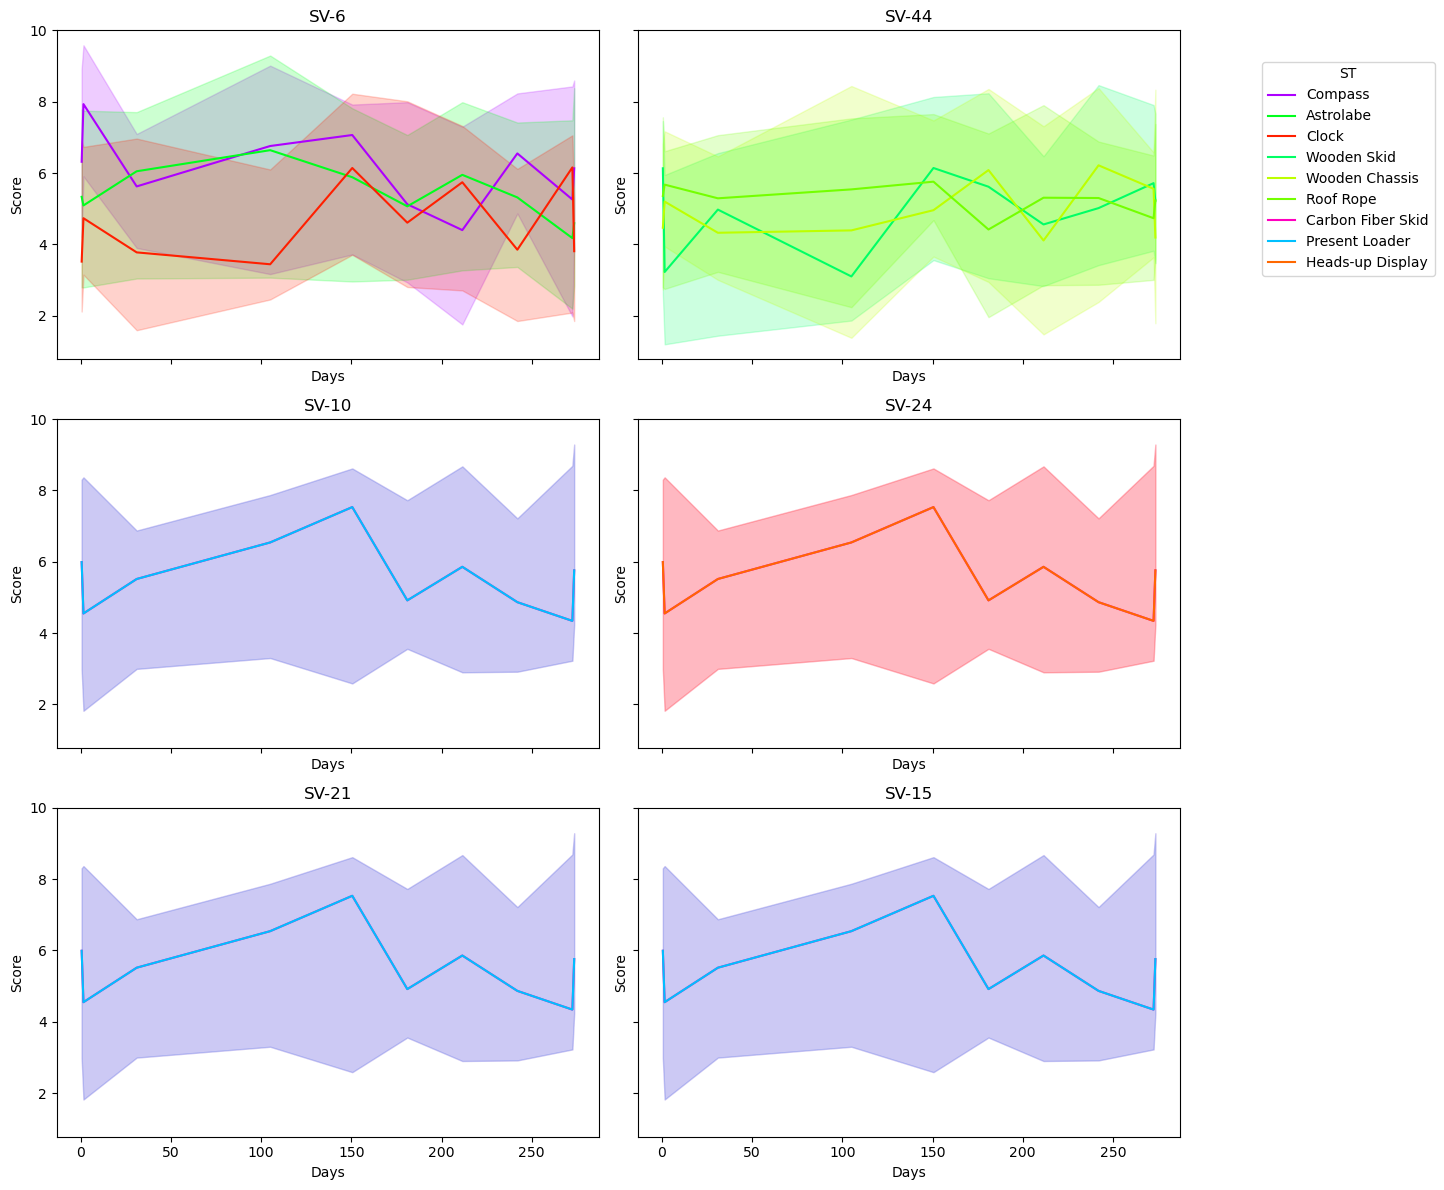

       SV                 ST  coef_30days   p_value      L_CI      U_CI
10  SV-44        Wooden Skid     0.065686  0.227013 -0.001363  0.005742
13   SV-6            Compass    -0.067099  0.252472 -0.006067  0.001594
12   SV-6              Clock     0.033064  0.522732 -0.002278  0.004482
0   SV-10  Carbon Fiber Skid     0.027642  0.609186 -0.002611  0.004454
4   SV-21  Carbon Fiber Skid     0.027642  0.609186 -0.002611  0.004454
1   SV-10     Present Loader     0.027642  0.609186 -0.002611  0.004454
2   SV-15  Carbon Fiber Skid     0.027642  0.609186 -0.002611  0.004454
3   SV-15     Present Loader     0.027642  0.609186 -0.002611  0.004454
7   SV-24   Heads-up Display     0.027642  0.609186 -0.002611  0.004454
6   SV-24  Carbon Fiber Skid     0.027642  0.609186 -0.002611  0.004454
5   SV-21     Present Loader     0.027642  0.609186 -0.002611  0.004454
9   SV-44     Wooden Chassis     0.018799  0.716378 -0.002754  0.004007
8   SV-44          Roof Rope    -0.017779  0.737752 -0.004062  0

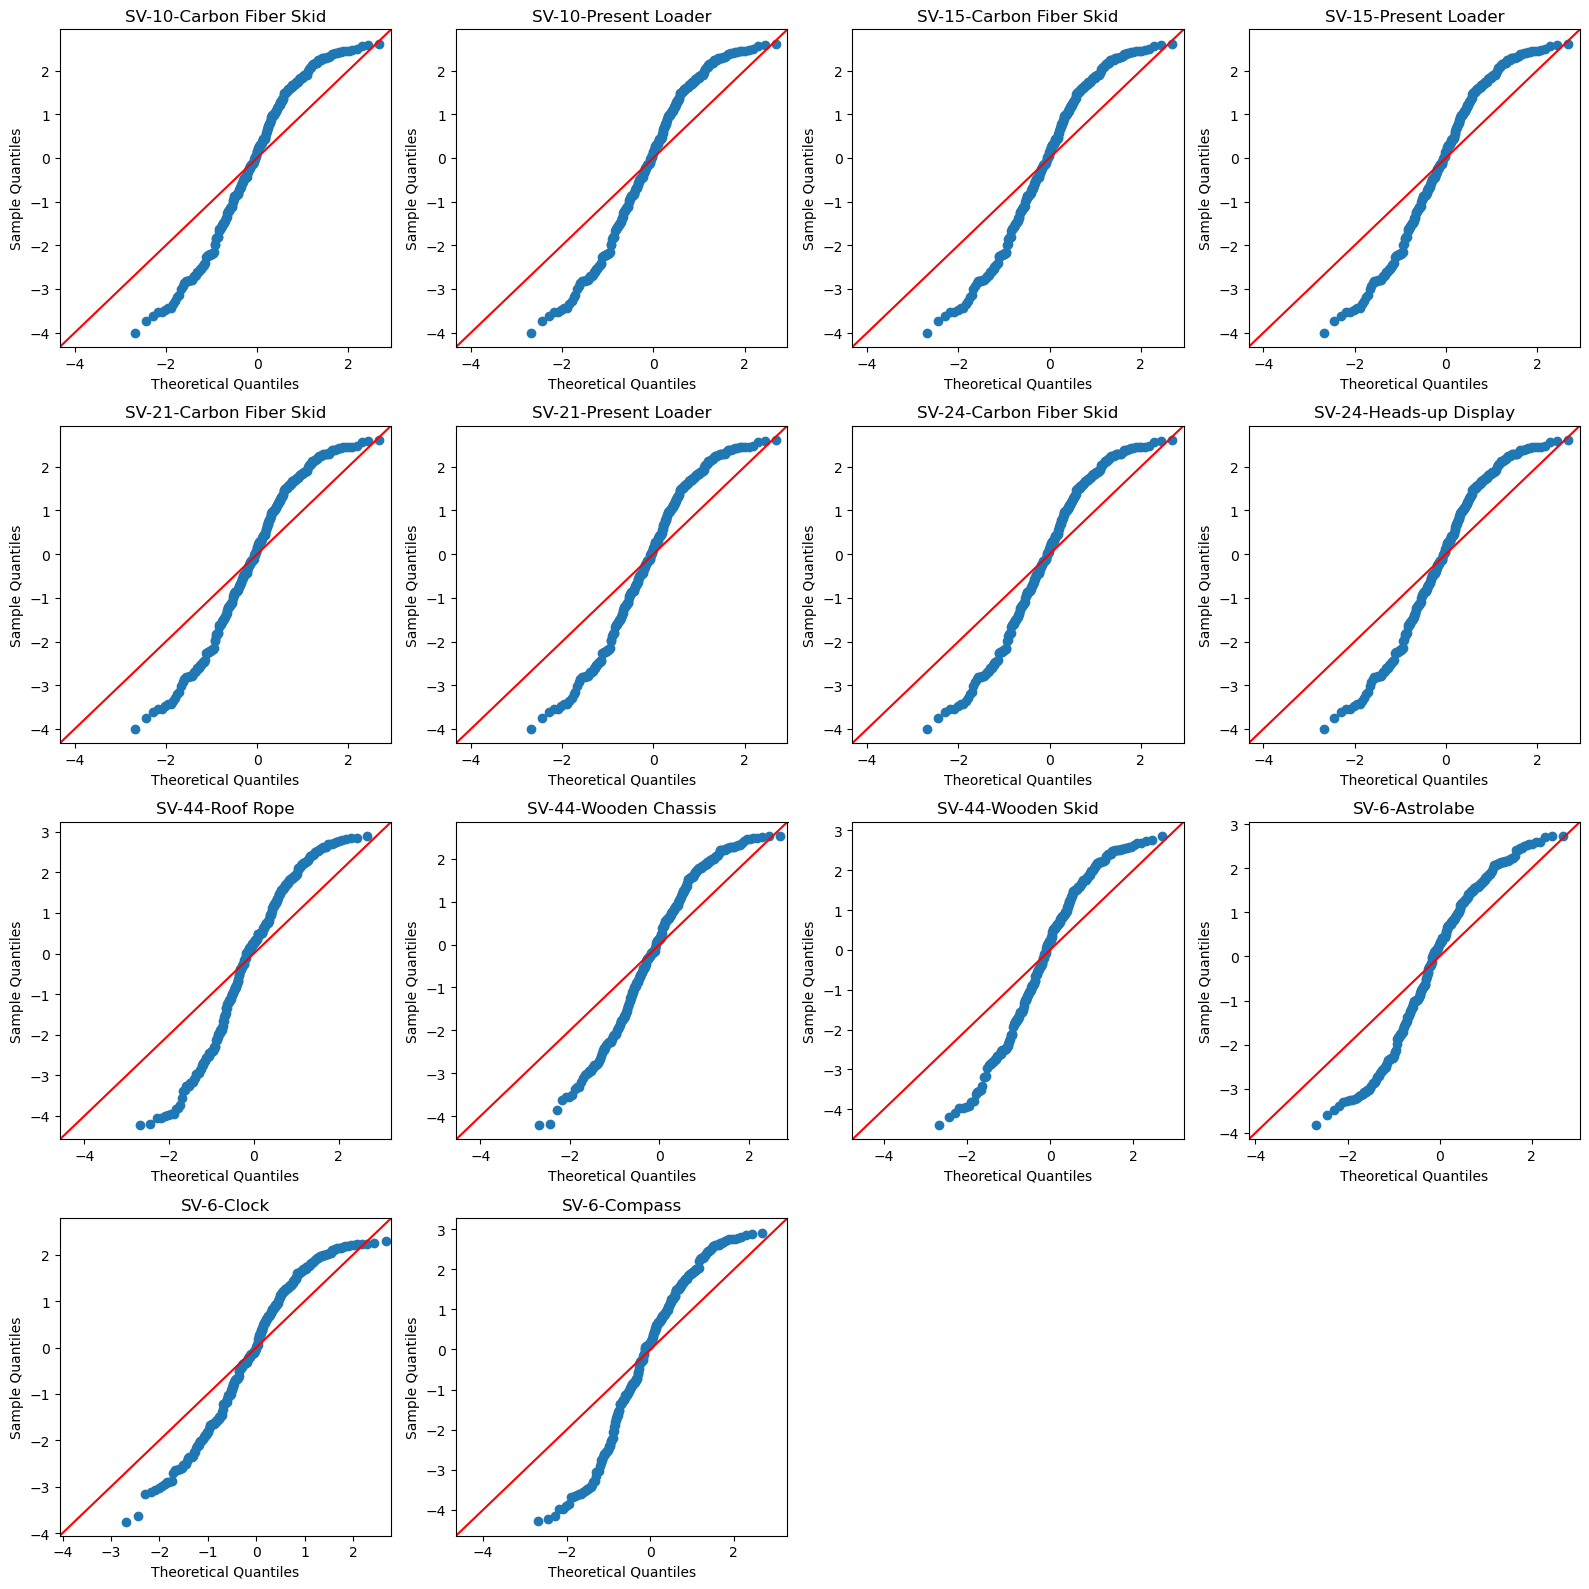

       SV                 ST  delta_30days   p_value    lambda
10  SV-44        Wooden Skid      0.075660  0.190166  0.648974
13   SV-6            Compass     -0.077732  0.211232  0.667358
0   SV-10  Carbon Fiber Skid      0.035705  0.538095  0.566340
1   SV-10     Present Loader      0.035705  0.538095  0.566340
4   SV-21  Carbon Fiber Skid      0.035705  0.538095  0.566340
5   SV-21     Present Loader      0.035705  0.538095  0.566340
2   SV-15  Carbon Fiber Skid      0.035705  0.538095  0.566340
3   SV-15     Present Loader      0.035705  0.538095  0.566340
7   SV-24   Heads-up Display      0.035705  0.538095  0.566340
6   SV-24  Carbon Fiber Skid      0.035705  0.538095  0.566340
12   SV-6              Clock      0.029202  0.576303  0.447392
11   SV-6          Astrolabe      0.020322  0.721954  0.585245
8   SV-44          Roof Rope     -0.018228  0.751304  0.696321
9   SV-44     Wooden Chassis      0.006526  0.908019  0.627911


In [8]:
analysis = GDDAnalysis("flatfiles\gdd.xlsx")

analysis.load_data()

analysis.plot_quantiles(n_bins=10)

ols_results = analysis.run_rlm()
print(ols_results)

boxcox_results = analysis.run_boxcox_analysis()
print(boxcox_results)

In [ ]:
# Heirarchy 1, Clunky

class ST:
    def __init__(self, name):
        self.name = name
        self.dataframes = {}
        self.results = {}

class SV:
    def __init__(self, name):
        self.name = name
        self.child = {}  # ST objects
        self.dataframes = {}
        self.results = {}

class RN:
    def __init__(self, name):
        self.name = name
        self.child = {}  # SV objects
        self.dataframes = {}
        self.results = {}

class SRR:
    def __init__(self, name):
        self.name = name
        self.child = {}  # RN objects
        self.dataframes = {}
        self.results = {}

def build_hierarchy(df):
    srr_dict = {}
    
    for _, row in df.iterrows():
        srr_name = row[0]
        rn_name = row[1]
        sv_name = row[2]
        st_name = row[3]

        # create objects if not exist
        if srr_name not in srr_dict:
            srr_dict[srr_name] = SRR(srr_name)
        srr_obj = srr_dict[srr_name]

        if rn_name not in srr_obj.child:
            srr_obj.child[rn_name] = RN(rn_name)
        rn_obj = srr_obj.child[rn_name]

        if sv_name not in rn_obj.child:
            rn_obj.child[sv_name] = SV(sv_name)
        sv_obj = rn_obj.child[sv_name]

        if st_name not in sv_obj.child:
            sv_obj.child[st_name] = ST(st_name)
        st_obj = sv_obj.child[st_name]

        # store row in dataframe
        if "raw" not in st_obj.dataframes:
            st_obj.dataframes["raw"] = []
        st_obj.dataframes["raw"].append(row)

    # Convert lists of rows to DataFrames
    for srr in srr_dict.values():
        for rn in srr.child.values():
            for sv in rn.child.values():
                for st in sv.child.values():
                    st_obj_df = pd.DataFrame(st.dataframes["raw"])
                    st.dataframes["raw"] = st_obj_df

    return srr_dict

layout = pd.read_excel(r"C:\Users\Drew\Documents\MyFiles\usaf\flatfiles\layout.xlsx", header=None).ffill()
shop = build_hierarchy(layout)
cfk = shop['GO'].child['Feliz'].child['SV-10'].child['Carbon Fiber Skid']
cfk.dataframes['raw']

In [ ]:
import pandas as pd
import scipy.stats as stats
import numpy as np
import warnings, time
from joblib import Parallel, delayed

class SVST:
    def __init__(self, sv, st, rn=None):
        self.sv = sv
        self.st = st
        self.rn = rn
        self.srr = set()  

        self.data = {}
        self.params = {}
        self.results = {}

    def fit_distributions(self, fit_config):
        fits = {}
        warnings.simplefilter("ignore", RuntimeWarning)
        for source, y in self.data.items():
            # If str in {NR, No data}, return str
            if isinstance(y, str):
                fits[source] = y
                continue
            config = fit_config[source]
            dist = config.get("dist")
            floc = config.get("floc")
            fscale = config.get("fscale")
            try:
                if floc is not None and fscale is not None:
                    params = dist.fit(y, floc=floc, fscale=fscale)
                elif floc is not None:
                    params = dist.fit(y, floc=floc)
                elif fscale is not None:
                    params = dist.fit(y, fscale=fscale)
                else:
                    params = dist.fit(y)
                fits[source] = params
            except Exception:
                print('exception')
                fits[source] = None
            self.params = fits

    def _print_name(self):
        print(self.sv, self.st)

    def _add_srr(self, srr):
        self.srr.add(srr)

    @property
    def srr_list(self):
        """Return SRRs as a list"""
        return list(self.srr)

def get_svst_objects(path):
    """From the workshop layout, collect RN, SV, ST, SRR_set"""
    df = pd.read_excel(path, header=None)
    df = df.ffill()
    objects = {}  
    for _, row in df.iterrows():
        srr, rn, sv, st = row[0], row[1], row[2], row[3]
        key = (sv, st)
        if key not in objects:
            objects[key] = SVST(sv, st, rn)
        objects[key]._add_srr(srr)
    return df, [(obj.sv, obj.st) for obj in objects.values()], list(objects.values())

# Notional
def generate_random_data(svst_pairs, n=20):
    rng = np.random.default_rng()
    def rand(a, b):
        return rng.uniform(a, b)

    models = {
    "source_A": stats.norm(loc=rand(7, 14), scale=rand(1, 3)),
    "source_B": stats.weibull_min(c=rand(1, 2), scale=rand(20, 50)),
    "source_C": stats.beta(a=rand(2, 12), b = rand(2, 12)),
    "source_D": stats.uniform(loc=rand(1, 10), scale=rand(5, 15))
    }

    df_dict = {}
    for source, dist in models.items():
        rows = []
        for sv, st in svst_pairs:
            if rng.random() >= 0.2:
                samples = dist.rvs(size=n)
                for val in samples:
                    rows.append({"sv": sv, "st": st, "data": val})
        df_dict[source] = pd.DataFrame(rows)
    return df_dict

def notional_srr_to_data(layout, data):
    layout_dict = {source: layout[0].unique().tolist() for source in data.keys()}
    return {source: np.random.choice(v, np.random.randint(1, 4)) for source, v in layout_dict.items()}

def attach_data_to_objects(svst, df_dict, layout_dict, data_col="data"):
    """Data sources are transferred from the dataframe to a np.array"""
    for obj in svst:
        obj.data = {}
        for source, df in df_dict.items():
            subset = df[(df["sv"] == obj.sv) & (df["st"] == obj.st)]
            if not subset.empty:
                obj.data[source] = np.array(subset[data_col])
            else:
                # Ex: If SRR set {GO, GC, SL} and SRR-data set {GC} intersect exist --> no data
                if set(obj.srr).intersection(set(layout_dict.get(source, []))):
                    obj.data[source] = "no data"
                else:
                    obj.data[source] = "NR"

def fit_svst_params(svst, fit_config, n_jobs=-1):
    """Fit all paramaters for all data for all svst"""
    def fit_obj(obj):
        obj.fit_distributions(fit_config)
        return obj
    svst_fit = Parallel(n_jobs, backend="threading")(delayed(fit_obj)(obj) for obj in svst)
    return svst_fit

def fit_svst_params2(svst, fit_config):
    for obj in svst:
        obj.fit_distributions(fit_config)
    return 

def notional_gryla():
    unique_sv = list(set(obj.sv for obj in svst))  # unique SVs from your SVST objects
    n_cases = 100
    unique_sv
    sources = ["source_A", "source_B", "source_C", "source_D"]

    rows = []
    for sv in unique_sv:
        for i in range(n_cases):
            row = [sv] + list(np.random.rand(len(sources)))  # random CDF values between 0 and 1
            rows.append(row)
    gryla = pd.DataFrame(rows, columns=["sv"] + sources)

    for col in sources:
        gryla[col] = gryla[col].astype(object)
    for col in sources:
        mask = np.random.rand(len(gryla)) < 0.2
        gryla.loc[mask, col] = 'hello'

    print(gryla.head(10))
    print("Shape:", gryla.shape)
    return gryla

def apply_cdf(cdf_values, source, obj, fit_config):

    params = obj.params[source]
    dist = fit_config[source]['dist']

    # apply CDF or SF
    result = []
    for v in cdf_values:
        if isinstance(v, (int, float, np.floating, np.integer)):
            try:
                result.append(dist.cdf(v, *params))
            except Exception:
                result.append("fit error")
        else:
            result.append(v)  # preserve string
    return result

fit_config = {
    "source_A": {"dist": stats.norm, "CDF": True, "return": [0,1]}, 
    "source_B": {"dist": stats.weibull_min, "CDF": False,  "return": [0,2], "floc": 0}, 
    "source_C": {"dist": stats.beta, "CDF": True, "return": [0,1], "floc": 0, "fscale": 1}, 
    "source_D": {"dist": stats.uniform, "CDF": False, "return": [0,1] }
}

layout, svst_pairs, svst = get_svst_objects(r"C:\Users\Drew\Documents\MyFiles\usaf\flatfiles\layout.xlsx")
data = generate_random_data(svst_pairs) # Notional!! --> flatfiles
layout_dict = notional_srr_to_data(layout, data) # Notional!! --> should exist
attach_data_to_objects(svst, data, layout_dict)

start = time.perf_counter()
svst_fit = fit_svst_params(svst, fit_config)
end = time.perf_counter()
print(f"Parallel joblib time: {end - start:.2f} seconds")

start = time.perf_counter()
fit_svst_params2(svst, fit_config)
end = time.perf_counter()
print(f"For loop time: {end - start:.2f} seconds")

gryla=notional_gryla()
gryla_array = gryla.iloc[:, 1:].to_numpy()
sv_unique = gryla["sv"].unique()
sv_index_map = {sv: i for i, sv in enumerate(sv_unique)}


Parallel joblib time: 0.49 seconds


For loop time: 0.36 seconds


In [15]:
svst[0].params

{'source_A': (np.float64(8.479125623400769), np.float64(2.493066870620484)),
 'source_B': 'no data',
 'source_C': (np.float64(7.664196375247336),
  np.float64(8.926548098726029),
  0,
  1),
 'source_D': (5.799233393467374, 6.3415632549904375)}

In [4]:
i = -1

In [12]:
i += 1
svst[i].params


{'source_A': 'no data',
 'source_B': (np.float64(1.66402887134909), 0, np.float64(60.66562440031265)),
 'source_C': (np.float64(6.381840810370281),
  np.float64(6.042935678574758),
  0,
  1),
 'source_D': (5.927393965364771, 6.672885654347071)}

In [190]:
svst[5]._print_name()

SV-22 Carbon Fiber Skid


      sv  source_A  source_B  source_C  source_D
0  SV-29  0.496042     hello     hello     hello
1  SV-29  0.477962  0.176296   0.51129  0.468402
2  SV-29     hello     hello  0.757971   0.29424
3  SV-29  0.701327     hello  0.455162     hello
4  SV-29   0.27585     hello     hello  0.978885
5  SV-29  0.344894     hello  0.668467  0.320131
6  SV-29  0.279563  0.701483  0.275473  0.750595
7  SV-29  0.132844     hello     hello  0.408003
8  SV-29  0.224801  0.144249  0.548764     hello
9  SV-29  0.736874  0.429338  0.381459   0.65095
Shape: (4900, 5)


In [14]:
fit_config['source_B']

{'dist': <scipy.stats._continuous_distns.weibull_min_gen at 0x2a0f37ae9c0>,
 'CDF': False,
 'return': [0, 2],
 'floc': 0}

In [133]:
svst[0].params

{'source_A': [np.float64(10.98032589709991), np.float64(1.3993321029421573)],
 'source_B': [np.float64(1.3071745611466075), np.float64(17.573757722604917)],
 'source_C': [np.float64(11.78038218444728), np.float64(4.544350723312271)],
 'source_D': [9.047743290968237, 6.720876101117026]}